In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.layers import Dense, LSTM
from tensorflow.keras.models import Sequential

In [26]:
import urllib.request

In [30]:
np.random.seed(42)

total_days = 750  # Примерно 3 года торговых дней
start_price = 4000  # Стартовая цена (как у индекса S&P 500 пару лет назад)
mu = 0.0002  # Средний дневной рост рынка
sigma = 0.01  # Дневная волатильность (хаос и колебания)

In [31]:
# модель симуляции биржевых цен
daily_returns = np.random.normal(mu, sigma, total_days)
price_path = start_price * np.exp(np.cumsum(daily_returns))
prices = price_path.reshape(-1, 1)

Эта модель называется Геометрическим броуновским движением. Крупные банки используют её потому, что обычная случайная генерация чисел (например, просто добавлять к цене ± 5 рублей) делает графики неестественными: цена может уйти в минус, а проценты роста не учитываются.
Данный код моделирует рынок с помощью трех шагов:

1. daily_returns = np.random.normal(mu, sigma, total_days)

Здесь мы создаем дневную доходность (процент изменения цены за каждый день).
• mu (0.0002) — это тренд. Представь, что экономика растет, компания развивается, и в среднем акция хочет расти на +0.02% в день.
• sigma (0.01) — это хаос (волатильность). Это новости, паника или радость трейдеров. Рынок штормит в среднем на ± 1% в день.
• np.random.normal каждый день выкидывает случайное число (процент). Чаще всего оно близко к mu, но иногда из-за хаоса (sigma) случаются резкие взлеты (+2%) или падения (-2%).

2. np.cumsum(daily_returns)

Это кумулятивная сумма (накопление).
Если в 1-й день рынок изменился на +1%, во 2-й на -0.5%, а в 3-й на +2%, то np.cumsum сложит их по цепочке:
• День 1: +1%
• День 2: +0.5% (так как 1 - 0.5)
• День 3: +2.5% (так как 0.5 + 2)
Так мы получаем непрерывную историю накопленных изменений рынка.

3. start_price * np.exp(...)

Это магия сложного процента.
• Вместо того чтобы просто прибавлять рубли к стартовой цене, мы умножаем стартовую цену (4000) на экспоненту np.exp от наших накопленных процентов.
• Почему именно экспонента? Она гарантирует, что цена акций математически никогда не упадет ниже нуля (акция не может стоить минус 50 рублей), и при этом рост будет рассчитываться как на реальной бирже — в процентах от текущей стоимости, а не от начальной.

In [33]:
# Масштабируем данные от 0 до 1 
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_prices = scaler.fit_transform(prices)

In [34]:
# 2. ПОДГОТОВКА «ВРЕМЕННЫХ ОКОН» (10 дней истории -> 11-й день)
window_size = 10
X, y = [], []

for i in range(len(scaled_prices) - window_size):
    X.append(scaled_prices[i : i + window_size])
    y.append(scaled_prices[i + window_size])

X = np.array(X)
y = np.array(y)


In [35]:
# Разделяем на тренировочную (80%) и тестовую (20%) выборки
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]


In [36]:
# 3. СТРОИМ И ОБУЧАЕМ LSTM-МОДЕЛЬ
model = Sequential(
    [
        LSTM(
            32,
            activation="tanh",
            input_shape=(window_size, 1),
            return_sequences=False,
        ),
        Dense(1),
    ]
)

model.compile(optimizer="adam", loss="mean_squared_error")

print("\n--- Запуск обучения LSTM ---")

model.fit(X_train, y_train, epochs=15, batch_size=16, verbose=1)



--- Запуск обучения LSTM ---
Epoch 1/15
37/37 [==============================] - 1s 2ms/step - loss: 0.0376
Epoch 2/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0048
Epoch 3/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0026
Epoch 4/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0023
Epoch 5/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0023
Epoch 6/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0022
Epoch 7/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0023
Epoch 8/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0021
Epoch 9/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0022
Epoch 10/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0021
Epoch 11/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0021
Epoch 12/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0020
Epoch 13/15
37/37 [

In [37]:
predictions_scaled = model.predict(X_test)

# Возвращаем значения из масштаба 
predictions = scaler.inverse_transform(predictions_scaled)
y_test_real = scaler.inverse_transform(y_test)

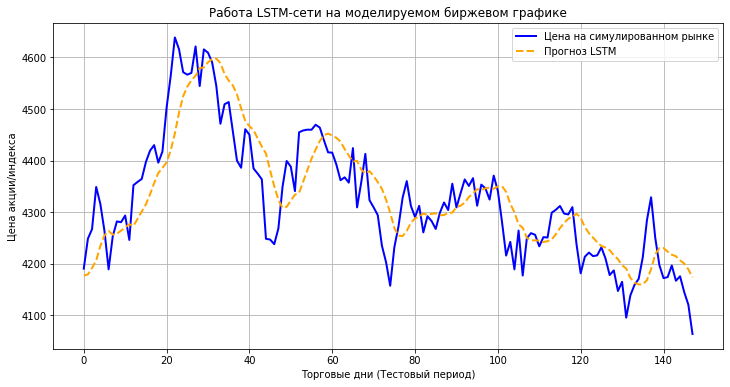

In [38]:
plt.figure(figsize=(12, 6))
plt.plot(y_test_real, label="Цена на симулированном рынке", color="blue", linewidth=2)
plt.plot(
    predictions,
    label="Прогноз LSTM",
    color="orange",
    linestyle="--",
    linewidth=2,
)
plt.title("Работа LSTM-сети на моделируемом биржевом графике")
plt.xlabel("Торговые дни (Тестовый период)")
plt.ylabel("Цена акции/индекса")
plt.legend()
plt.grid(True)
plt.show()

In [40]:
from tensorflow.keras.layers import SimpleRNN

In [43]:
# 1. Создаем точно такую же структуру, но на базе SimpleRNN
model_rnn = Sequential(
    [
        SimpleRNN(32, activation="tanh", input_shape=(window_size, 1)),
        Dense(1),
    ]
)

model_rnn.compile(optimizer="adam", loss="mean_squared_error")

In [44]:
# 2. Обучаем на тех же данных
model_rnn.fit(X_train, y_train, epochs=15, batch_size=16, verbose=1)

Epoch 1/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0046
Epoch 2/15
37/37 [==============================] - 0s 2ms/step - loss: 0.0019
Epoch 3/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0014
Epoch 4/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0013
Epoch 5/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0012
Epoch 6/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0014
Epoch 7/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0015
Epoch 8/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0011
Epoch 9/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0011
Epoch 10/15
37/37 [==============================] - 0s 1ms/step - loss: 0.0010
Epoch 11/15
37/37 [==============================] - 0s 1ms/step - loss: 9.7614e-04
Epoch 12/15
37/37 [==============================] - 0s 1ms/step - loss: 9.4884e-04
Epoch 13/15
37/37 [======================

In [45]:
predictions_rnn_scaled = model_rnn.predict(X_test)
predictions_rnn = scaler.inverse_transform(predictions_scaled_rnn if 'predictions_scaled_rnn' in locals() else predictions_rnn_scaled)


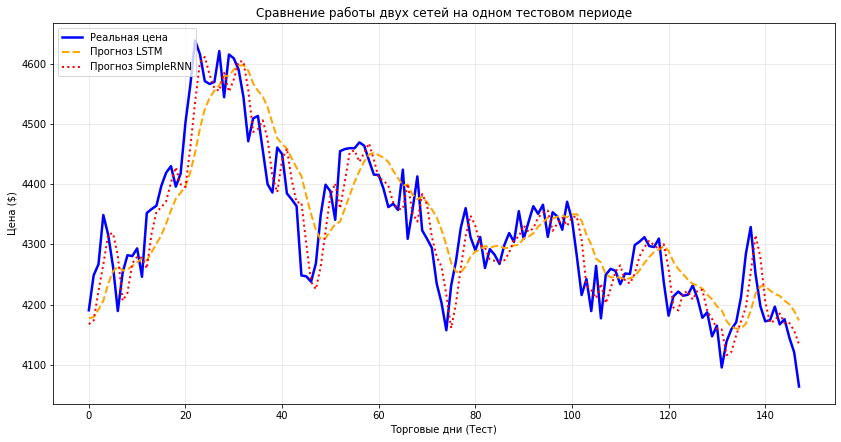

In [46]:
# LSTM vs SimpleRNN

plt.figure(figsize=(14, 7))

plt.plot(y_test_real, label="Реальная цена", color="blue", linewidth=2.5)

# прогноз LSTM
plt.plot(
    predictions,
    label="Прогноз LSTM",
    color="orange",
    linestyle="--",
    linewidth=2,
)

# прогноз SimpleRNN
plt.plot(
    predictions_rnn,
    label="Прогноз SimpleRNN",
    color="red",
    linestyle=":",
    linewidth=2,
)

plt.title("Сравнение работы двух сетей на одном тестовом периоде")
plt.xlabel("Торговые дни (Тест)")
plt.ylabel("Цена ($)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [50]:
def calculate_mape(y_true, y_pred):
    # Функция для расчета ошибки в процентах (%)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


# Считаем метрики для твоей LSTM
mae_lstm = mean_absolute_error(y_test_real, predictions)
rmse_lstm = np.sqrt(mean_squared_error(y_test_real, predictions))
mape_lstm = calculate_mape(y_test_real, predictions)

# Считаем метрики для новой SimpleRNN
mae_rnn = mean_absolute_error(y_test_real, predictions_rnn)
rmse_rnn = np.sqrt(mean_squared_error(y_test_real, predictions_rnn))
mape_rnn = calculate_mape(y_test_real, predictions_rnn)

# Выводим красивую сравнительную таблицу в консоль
print("\n" + "=" * 50)
print(f"{'МЕТРИКА':<20} | {'LSTM (Долгая память)':<20} | {'SimpleRNN (Обычная)'}")
print("-" * 50)
print(f"{'MAE (ошибка в $)':<20} | {mae_lstm:<20.2f} | {mae_rnn:.2f}")
print(f"{'RMSE (штраф за пики)':<20} | {rmse_lstm:<20.2f} | {rmse_rnn:.2f}")
print(f"{'MAPE (ошибка в %)':<20} | {mape_lstm:<20.2f}% | {mape_rnn:.2f}%")
print("=" * 50)




МЕТРИКА              | LSTM (Долгая память) | SimpleRNN (Обычная)
--------------------------------------------------
MAE (ошибка в $)     | 52.18                | 38.19
RMSE (штраф за пики) | 65.52                | 47.42
MAPE (ошибка в %)    | 1.21                % | 0.88%


In [71]:
# 7. ПОДСЧЕТ ТОЧНОСТИ МОДЕЛЕЙ ПО НАПРАВЛЕНИЮ 
import numpy as np

# Автоматически определяем, под каким именем сохранен прогноз LSTM в памяти
if 'pred_lstm' in locals():
    lstm_source = pred_lstm
elif 'predictions' in locals():
    lstm_source = predictions
else:
    raise NameError("Ошибка: Не найден массив с прогнозом LSTM. Проверь, как называется переменная.")

# Автоматически определяем прогноз SimpleRNN
if 'pred_rnn' in locals():
    rnn_source = pred_rnn
elif 'predictions_rnn' in locals():
    rnn_source = predictions_rnn
else:
    raise NameError("Ошибка: Не найден массив с прогнозом SimpleRNN. Проверь, как называется переменная.")

# То же самое для реальных цен
if 'y_test_real' in locals():
    true_source = y_test_real
else:
    raise NameError("Ошибка: Не найден массив y_test_real с реальными ценами.")

# Переводим в плоские массивы для расчетов
true_prices = true_source.flatten()
lstm_prices = lstm_source.flatten()
rnn_prices = rnn_source.flatten()

# Берем цену последнего дня из обучения как точку отсчета для первого дня теста
last_train_price = scaler.inverse_transform(y_train[-1].reshape(-1, 1)).flatten()
real_with_prev = np.insert(true_prices, 0, last_train_price)

# 1. Реальное направление рынка (1 - выросло, 0 - упало)
real_direction = (np.diff(real_with_prev) > 0).astype(int)

# 2. Прогнозы направления моделей
lstm_direction = (lstm_prices > real_with_prev[:-1]).astype(int)
rnn_direction = (rnn_prices > real_with_prev[:-1]).astype(int)

# 3. Считаем процент совпадений (Accuracy)
accuracy_lstm = np.mean(real_direction == lstm_direction) * 100
accuracy_rnn = np.mean(real_direction == rnn_direction) * 100

# Выводим отчет
print(f" Направление угадано верно (LSTM):      {accuracy_lstm:.1f}%")
print(f" Направление угадано верно (SimpleRNN):  {accuracy_rnn:.1f}%")
print(f" Всего тестовых дней оценено: {len(real_direction)}")

 Направление угадано верно (LSTM):      54.8%
 Направление угадано верно (SimpleRNN):  50.0%
 Всего тестовых дней оценено: 42


In [61]:
csv_filename = "data/Data_brent_5y.csv"

print(f"Читаем данные из файла: {csv_filename}...")
df = pd.read_csv(csv_filename)

# Извлекаем цены закрытия из колонки 'close'
prices = df["close"].values.reshape(-1, 1)
print(f"Успешно загружено {len(prices)} торговых дней.")

# Масштабируем данные от 0 до 1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_prices = scaler.fit_transform(prices)

Читаем данные из файла: data/Data_brent_5y.csv...
Успешно загружено 1315 торговых дней.


In [62]:
# 2. ПОДГОТОВКА СКОЛЬЗЯЩЕГО ОКНА (10 дней истории -> 11-й день)
window_size = 20
X, y = [], []

for i in range(len(scaled_prices) - window_size):
    X.append(scaled_prices[i : i + window_size])
    y.append(scaled_prices[i + window_size])

X, y = np.array(X), np.array(y)

# Выделяем ровно последние 42 торговых дня под тест
test_days = 42
X_train, X_test = X[:-test_days], X[-test_days:]
y_train, y_test = y[:-test_days], y[-test_days:]

In [63]:
# Модель 1: LSTM
model_lstm = Sequential(
    [
        LSTM(32, activation="tanh", input_shape=(window_size, 1)),
        Dense(1),
    ]
)
model_lstm.compile(optimizer="adam", loss="mean_squared_error")
model_lstm.fit(X_train, y_train, epochs=20, batch_size=8, verbose=0)
pred_lstm = scaler.inverse_transform(model_lstm.predict(X_test))

# Модель 2: SimpleRNN
model_rnn = Sequential(
    [
        SimpleRNN(32, activation="tanh", input_shape=(window_size, 1)),
        Dense(1),
    ]
)
model_rnn.compile(optimizer="adam", loss="mean_squared_error")
model_rnn.fit(X_train, y_train, epochs=20, batch_size=8, verbose=0)
pred_rnn = scaler.inverse_transform(model_rnn.predict(X_test))

# Реальные цены тестового месяца
y_test_real = scaler.inverse_transform(y_test)

In [68]:
# Считаем mae ошибку 
mae_lstm = mean_absolute_error(y_test_real, pred_lstm)
mae_rnn = mean_absolute_error(y_test_real, pred_rnn)

# Считаем точность угадывания направления (Accuracy)
last_train_price = scaler.inverse_transform(y_train[-1].reshape(-1, 1)).flatten()
real_with_prev = np.insert(y_test_real.flatten(), 0, last_train_price)

real_direction = (np.diff(real_with_prev) > 0).astype(int)
lstm_direction = (pred_lstm.flatten() > real_with_prev[:-1]).astype(int)
rnn_direction = (pred_rnn.flatten() > real_with_prev[:-1]).astype(int)

accuracy_lstm = np.mean(real_direction == lstm_direction) * 100
accuracy_rnn = np.mean(real_direction == rnn_direction) * 100

print(f"{'МЕТРИКА ОЦЕНКИ':<25} | {'LSTM (С памятью)':<18} | {'SimpleRNN'}")
print(f"{'Средняя ошибка (MAE)':<25} | {mae_lstm:<18.2f} | {mae_rnn:.2f}")
print(f"{'Точность направления (%)':<25} | {accuracy_lstm:<17.1f}% | {accuracy_rnn:.1f}%")


МЕТРИКА ОЦЕНКИ            | LSTM (С памятью)   | SimpleRNN
Средняя ошибка (MAE)      | 2.52               | 2.59
Точность направления (%)  | 54.8             % | 50.0%


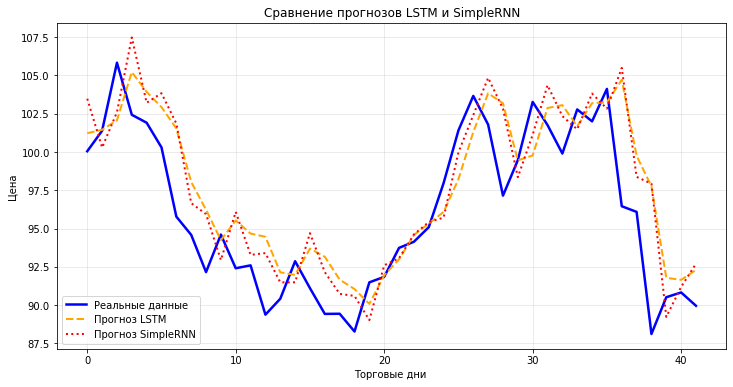

In [66]:
plt.figure(figsize=(12, 6))
plt.plot(
    y_test_real,
    label="Реальные данные ",
    color="blue",
    linewidth=2.5,
)
plt.plot(pred_lstm, label="Прогноз LSTM", color="orange", linestyle="--", linewidth=2)
plt.plot(pred_rnn, label="Прогноз SimpleRNN", color="red", linestyle=":", linewidth=2)
plt.title(
    "Сравнение прогнозов LSTM и SimpleRNN"
)
plt.xlabel("Торговые дни ")
plt.ylabel("Цена")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()